# Working with Protein Structures

The `Structure` class is the core data type for representing macromolecular structures throughout proto-tools. It wraps PDB and CIF files behind a unified interface that provides sequence extraction, chain inspection, format conversion, and interactive 3D visualization. Most tool outputs that involve 3D coordinates return `Structure` objects, so understanding this class is essential for working with structure prediction, inverse folding, and structure alignment tools.

## Loading a Structure

A `Structure` can be created from a file path using `Structure.from_file()`, or by passing a raw content string directly to the constructor. The `b_factor_type` parameter documents what the B-factor column in the file represents — for experimental structures from the PDB this is typically `"temperature_factor"`, while for predicted structures from tools like AlphaFold or ESMFold it would be `"pLDDT"` or `"normalized_pLDDT"`.

Here we load an experimental structure of Green Fluorescent Protein (GFP), a 238-residue protein originally isolated from the jellyfish *Aequorea victoria*.

In [1]:
from proto_tools.entities.structures.examples import GFP_CIF_PATH
from proto_tools.entities.structures.structure import Structure

# Load GFP from a CIF file; b_factor_type documents the crystallographic temperature factor
gfp_structure = Structure.from_file(
    GFP_CIF_PATH,
    b_factor_type="temperature_factor",
)

## Inspecting Structure Properties

The `Structure` object exposes chain information and residue counts directly as properties. These are useful for validating that a structure loaded correctly, confirming the number of chains and residues matches expectations, and preparing inputs to downstream tools that require specific chain IDs.

In [2]:
print(f"Number of chains: {gfp_structure.num_chains}")
print(f"Chain IDs: {gfp_structure.get_chain_ids()}")
print(f"Number of residues: {gfp_structure.num_residues}")

Number of chains: 1
Chain IDs: ['A']
Number of residues: 228


## Extracting Chain Sequences

The `get_chain_sequence` method extracts the amino acid sequence for a given chain as a one-letter code string. Setting `remove_non_standard=True` strips non-standard residues (represented as `X`) and gaps, which is useful when passing sequences to tools that only accept canonical amino acids.

In [3]:
sequence = gfp_structure.get_chain_sequence("A", remove_non_standard=True)
print(f"Chain A sequence ({len(sequence)} residues):")
print(sequence)

Chain A sequence (228 residues):
SKGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKFICTTGKLPVPWPTLVTTLtVQCFARYPDHMKQHDFFKSAMPEGYVQERTIFFKDDGNYKTRAEVKFEGDTLVNRIELKGIDFKEDGNILGHKLEYNYNHHKVYITADKQKNGIKVNFKTRHNIEDGSVQLADHYQQNTPIGDGPVLLPDNHYLHTHSKLSKDPNEKRDHMVLLEFVTAAGITL


## Visualizing the Structure

The `visualize` method renders an interactive 3D view using py3Dmol. You can rotate, zoom, and pan to inspect the fold. The `color_by` parameter controls coloring: `"bfactor"` applies a gradient over the B-factor values, while `"chain"` assigns each chain a distinct color. When `b_factor_type` is set to anything other than `"unspecified"`, `visualize` defaults to B-factor coloring automatically.

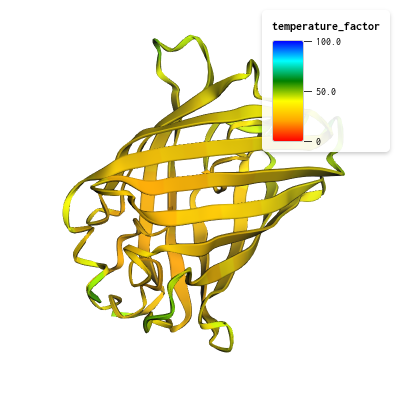

In [4]:
# Color by B-factor (crystallographic temperature factor) with a gradient legend
gfp_structure.visualize(color_by="bfactor")